# Прогноз снижения покупательской активности клиентов интернет-магазина «В один клик»

## Описание проекта

Интернет-магазин «В один клик» продаёт разные товары: для детей, для дома, мелкую бытовую технику, косметику и даже продукты. Отчёт магазина за прошлый период показал, что активность покупателей начала снижаться. Привлекать новых клиентов уже не так эффективно: о магазине и так знает большая часть целевой аудитории. Возможный выход — удерживать активность постоянных клиентов с помощью персонализированных предложений.

Мы построим модель, которая предскажет вероятность снижения покупательской активности клиента в следующие три месяца, а затем, используя предсказания модели и данные о прибыльности клиентов, выделим сегмент покупателей и предложим, как увеличить его покупательскую активность.

В нашем распоряжении четыре таблицы:
* market_file.csv — данные о поведении покупателя на сайте, о коммуникациях с покупателем и его продуктовом поведении, а также целевой признак «Покупательская активность»;
* market_money.csv — выручка от покупателя за три последних периода;
* market_time.csv — время, проведённое покупателем на сайте, за два периода;
* money.csv — среднемесячная прибыль от покупателя за последние 3 месяца.

В этом исследовании:
* Мы загрузим и предобработаем данные
* Проведём исследовательский анализ и отберём клиентов с покупательской активностью не менее трёх месяцев
* Объединим таблицы и проведём корреляционный анализ
* С помощью пайплайнов обучим четыре модели: KNeighborsClassifier, DecisionTreeClassifier, LogisticRegression и SVC, подберём гиперпараметры и выберем лучшую модель по метрике ROC-AUC
* Оценим важность признаков методом SHAP
* Выделим сегмент покупателей, исследуем его и подготовим предложения для бизнеса

## Импорт библиотек

In [1]:
%pip install phik shap -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import phik
import shap
import math
import numpy as np

from typing import List, Dict, Optional
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

## Вспомогательные функции и константы

In [3]:
RANDOM_STATE=42
TEST_SIZE = 0.25

In [4]:
def first_step(frame_name: str, sep: str = ',', decimal: str = '.'):
    full_path = '/datasets/' + frame_name
    dataset = pd.read_csv(full_path, sep=sep, decimal=decimal)
    dataset.info();
    return dataset

### Гистограммы количественных признаков

In [5]:
def multy_nice_plot(df: pd.DataFrame, columns_dict: Dict[str, str], logy=False, kde=False):
    for column, params in columns_dict.items():
        legend = params.get('legend')
        bins = params.get('bins', 10)
        if legend:
            hist = sns.histplot(
                data=df[column],
                bins=bins,
                log_scale=(False, logy),
                kde=kde,
            )
            hist.legend(title='')
        else:
            hist = sns.histplot(
                data=df[column],
                bins=bins,
                log_scale=(False, logy),
                kde=kde,
            )
        hist.set_xlabel(params['x_label'])
        hist.set_ylabel('Частота')
        hist.set_title(params['title'])
        plt.show()

### Диаграммы категориальных признаков

In [6]:
def category_plot(df: pd.DataFrame, columns: Optional[List[str]] = None) -> None:
    columns_list = columns or df.select_dtypes(include=["object"]).columns.tolist()

    if not columns_list:
        return

    n_plots = len(columns_list)
    n_cols = min(3, n_plots)
    n_rows = math.ceil(n_plots / n_cols)

    subplot_width = 5
    subplot_height = 5

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(subplot_width * n_cols, subplot_height * n_rows),
        squeeze=False,
    )

    axes_flat = axes.flatten()

    for ax, column in zip(axes_flat, columns_list):
        counts = df[column].value_counts()

        counts.plot(
            kind="pie",
            ax=ax,
            autopct="%1.1f%%",
            ylabel="",
            textprops={"fontsize": 12},
        )
        ax.set_title(column, fontsize=15)
        ax.set_aspect("equal")

    for ax in axes_flat[len(columns_list):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

### Тепловая карта корреляций

In [7]:
def nice_heatmap(df, figsize=(16, 12)):
    df_corr = df
    if 'id' in df.columns:
        df_corr = df.drop(columns=['id']).copy()
    
    phik_corr = df_corr.phik_matrix(
        interval_cols=df_corr.select_dtypes(include='number').columns
    )
    
    plt.figure(figsize=figsize, dpi=150)
    
    ax = sns.heatmap(
        phik_corr,
        cmap='YlOrRd',
        annot=True, 
        fmt='.2f',
        vmin=0,
        vmax=1,
    )
    ax.set_title('Phi_K корреляционная матрица')
    
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()

## Шаг 1. Загрузка данных

In [8]:
users_data = first_step('market_file.csv')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 13 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   id                                   1300 non-null   int64  
 1   Покупательская активность            1300 non-null   object 
 2   Тип сервиса                          1300 non-null   object 
 3   Разрешить сообщать                   1300 non-null   object 
 4   Маркет_актив_6_мес                   1300 non-null   float64
 5   Маркет_актив_тек_мес                 1300 non-null   int64  
 6   Длительность                         1300 non-null   int64  
 7   Акционные_покупки                    1300 non-null   float64
 8   Популярная_категория                 1300 non-null   object 
 9   Средний_просмотр_категорий_за_визит  1300 non-null   int64  
 10  Неоплаченные_продукты_штук_квартал   1300 non-null   int64  
 11  Ошибка_сервиса                

In [9]:
users_data.head()

,id,Покупательская активность,Тип сервиса,Разрешить сообщать,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Популярная_категория,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит
0,215348,Снизилась,премиум,да,3.4,5,121,0.00,Товары для детей,6,2,1,5
1,215349,Снизилась,премиум,да,4.4,4,819,0.75,Товары для детей,4,4,2,5
2,215350,Снизилась,стандартт,нет,4.9,3,539,0.14,Домашний текстиль,5,2,1,5
3,215351,Снизилась,стандартт,да,3.2,5,896,0.99,Товары для детей,5,0,6,4
4,215352,Снизилась,стандартт,нет,5.1,3,1064,0.94,Товары для детей,3,2,3,2


In [10]:
revenue = first_step('market_money.csv')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       3900 non-null   int64  
 1   Период   3900 non-null   object 
 2   Выручка  3900 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 91.5+ KB


In [11]:
revenue.head()

,id,Период,Выручка
0,215348,препредыдущий_месяц,0.0
1,215348,текущий_месяц,3293.1
2,215348,предыдущий_месяц,0.0
3,215349,препредыдущий_месяц,4472.0
4,215349,текущий_месяц,4971.6


In [12]:
timings = first_step('market_time.csv')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2600 entries, 0 to 2599
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2600 non-null   int64 
 1   Период  2600 non-null   object
 2   минут   2600 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 61.1+ KB


In [13]:
timings.head()

,id,Период,минут
0,215348,текущий_месяц,14
1,215348,предыдцщий_месяц,13
2,215349,текущий_месяц,10
3,215349,предыдцщий_месяц,12
4,215350,текущий_месяц,13


В значениях столбца «Период» есть опечатка: заменим «предыдцщий_месяц» на «предыдущий_месяц».

In [14]:
timings.replace('предыдцщий_месяц', 'предыдущий_месяц', inplace=True)

In [15]:
avg_3m_profit = first_step('money.csv', sep=';', decimal=',')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       1300 non-null   int64  
 1   Прибыль  1300 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 20.4 KB


In [16]:
avg_3m_profit.head()

,id,Прибыль
0,215348,0.98
1,215349,4.16
2,215350,3.13
3,215351,4.87
4,215352,4.21


Мы загрузили четыре таблицы. Данные соответствуют описанию: набор столбцов и типы данных совпадают. В файле money.csv разделитель — точка с запятой, а десятичный разделитель — запятая, это мы учли при загрузке.

## Шаг 2. Предобработка данных

### Проверка пропусков

In [17]:
users_data.isna().sum()

id                                     0
Покупательская активность              0
Тип сервиса                            0
Разрешить сообщать                     0
Маркет_актив_6_мес                     0
Маркет_актив_тек_мес                   0
Длительность                           0
Акционные_покупки                      0
Популярная_категория                   0
Средний_просмотр_категорий_за_визит    0
Неоплаченные_продукты_штук_квартал     0
Ошибка_сервиса                         0
Страниц_за_визит                       0
dtype: int64

In [18]:
revenue.isna().sum()

id         0
Период     0
Выручка    0
dtype: int64

In [19]:
timings.isna().sum()

id        0
Период    0
минут     0
dtype: int64

In [20]:
avg_3m_profit.isna().sum()

id         0
Прибыль    0
dtype: int64

Пропусков нет ни в одной из таблиц.

### Поиск дубликатов

In [21]:
users_data.duplicated().sum()

0

In [22]:
revenue.duplicated().sum()

0

In [23]:
timings.duplicated().sum()

0

In [24]:
avg_3m_profit.duplicated().sum()

0

Дубликатов нет ни в одной из таблиц.

## Шаг 3. Исследовательский анализ данных

### Количественные признаки

#### Данные о покупателях (market_file)

In [25]:
COLUMNS_PARAMETERS = {
    'Маркет_актив_6_мес': {
        'x_label': 'количество',
        'title': 'среднее количество коммуникаций за полгода',
        'bins': 50,
    },
    'Маркет_актив_тек_мес': {
        'x_label': 'количество',
        'title': 'количество коммуникаций за месяц',
        'bins': 50,
    },
    'Длительность': {
        'x_label': 'дни',
        'title': 'время с момента регистрации',
        'bins': 50,
    },
    'Акционные_покупки': {
        'x_label': 'доля',
        'title': 'доля акционных покупок',
        'bins': 50,
    },
    'Средний_просмотр_категорий_за_визит': {
        'x_label': 'количество',
        'title': 'среднее количество просмотренных категорий',
        'bins': 6,
    },
    'Неоплаченные_продукты_штук_квартал': {
        'x_label': 'штуки',
        'title': 'число неоплаченных товаров в корзине за 3 месяца',
        'bins': 11,
    },
    'Ошибка_сервиса': {
        'x_label': 'количество',
        'title': 'число сбоев за 3 месяца',
        'bins': 10,
    },
    'Страниц_за_визит': {
        'x_label': 'страницы',
        'title': 'среднее количество просмотренных страниц',
        'bins': 20,
    },
}

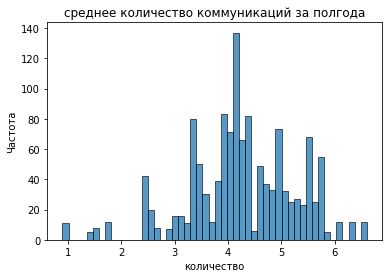

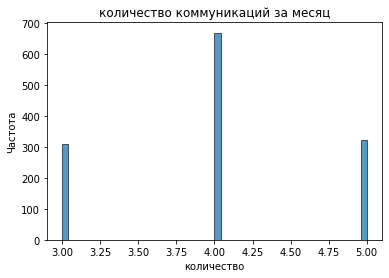

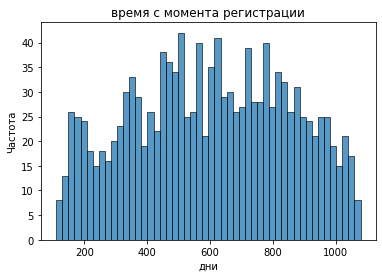

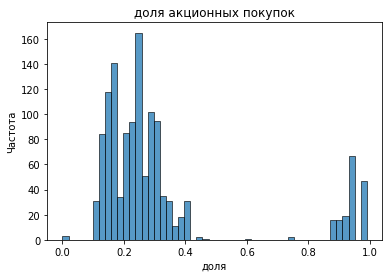

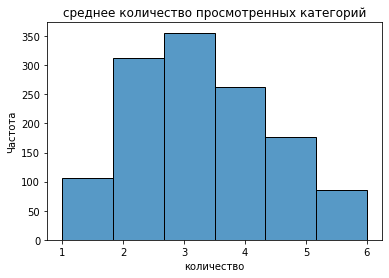

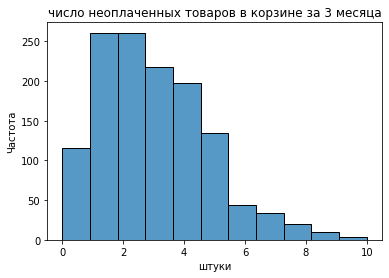

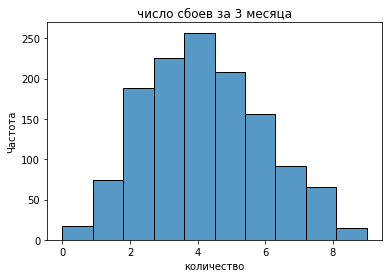

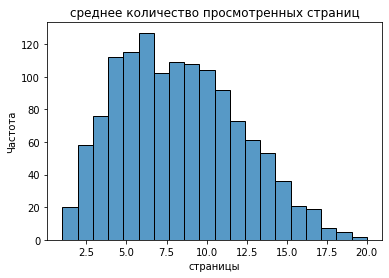

In [26]:
multy_nice_plot(users_data, COLUMNS_PARAMETERS)

Видно, что за последний месяц поменялся паттерн маркетинговых коммуникаций с клиентами. Причём в последний месяц признак даже скорее поменял тип: перешёл из численного в категориальный порядковый. Тем не менее, мы не можем предполагать что и дальше в коммуникациях с клиентом сохранится именно такой паттерн: три, четыре или пять коммуникаций в месяц. Если же мы переделаем признак в порядковый, то мы обучим модель именно на этих значениях, что может привести к падению точности предсказаний в будущем.

В отношении к акционным покупкам явно выделяются два кластера: те, кто покупают преимущественно по акции и те, кто пользуются акционными предложениями при возможности.

#### Данные о выручке (market_money)

In [27]:
REVENUE_PARAMETERS = {
    'Выручка': {
        'x_label': 'условные единицы',
        'title': 'Выручка за период',
        'bins': 50,
    },
}

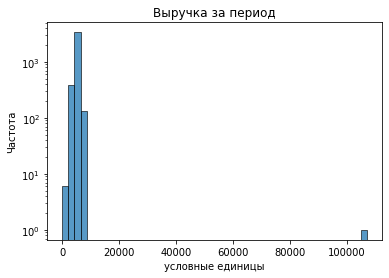

In [28]:
multy_nice_plot(revenue, REVENUE_PARAMETERS, logy=True)

In [29]:
revenue[revenue['Выручка'] > 20000]

,id,Период,Выручка
98,215380,текущий_месяц,106862.2


Похоже, что данные пользователя с id 215380 нужно удалить из всех таблиц: его выручка на два порядка выше типичной. Если только «В один клик» не продаёт дорогие нишевые товары — это надо будет уточнить у заказчика. Пока же трактуем это значение как выброс: крайне маловероятно, что такая сделка была бы всего одна.

In [30]:
for df in [users_data, revenue, timings, avg_3m_profit]:
    df.drop(df[df['id'] == 215380].index, inplace=True)

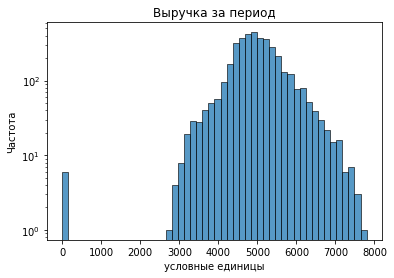

In [31]:
multy_nice_plot(revenue, REVENUE_PARAMETERS, logy=True)

#### Данные о времени на сайте (market_time)

In [32]:
TIMINGS_PARAMETERS = {
    'минут': {
        'x_label': 'минуты',
        'title': 'Время проведённое на сайте в текущем месяце',
        'bins': 19,
    },
}

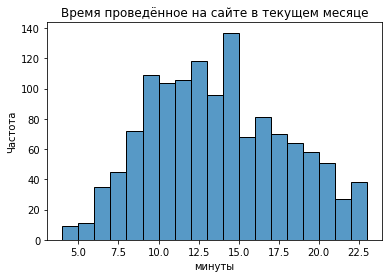

In [33]:
multy_nice_plot(timings[timings['Период'] == 'текущий_месяц'], TIMINGS_PARAMETERS)

In [34]:
TIMINGS_PARAMETERS = {
    'минут': {
        'x_label': 'минуты',
        'title': 'Время проведённое на сайте в предыдущем месяце',
        'bins': 19,
    },
}

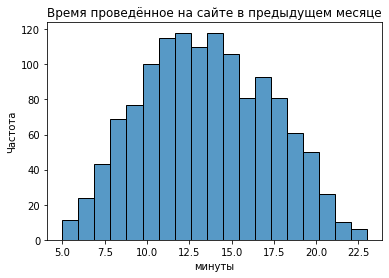

In [35]:
multy_nice_plot(timings[timings['Период'] == 'предыдущий_месяц'], TIMINGS_PARAMETERS)

Видно, что распределение времени на сайте в текущем месяце изменилось по сравнению с предыдущим.

#### Данные о прибыли (money)

In [36]:
MONTH_REV_PARAMETERS = {
    'Прибыль': {
        'x_label': 'условные единицы',
        'title': 'Прибыль, полученная от пользователя',
        'bins': 50,
    },
}

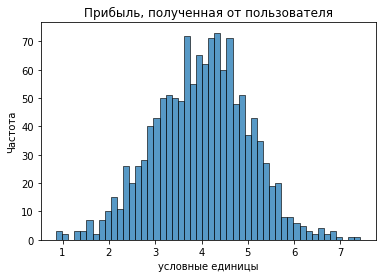

In [37]:
multy_nice_plot(avg_3m_profit, MONTH_REV_PARAMETERS)

### Категориальные признаки

#### Данные о покупателях (market_file)

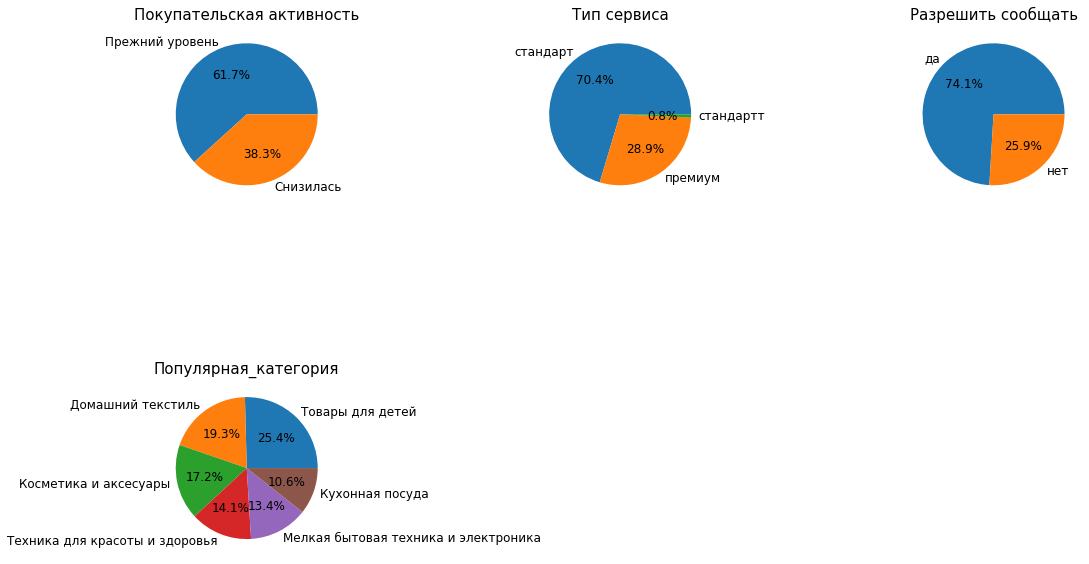

In [38]:
category_plot(users_data)

Видим опечатку в значениях типа сервиса: заменим «стандартт» на «стандарт».

In [39]:
users_data['Тип сервиса'].replace('стандартт', 'стандарт', inplace=True)

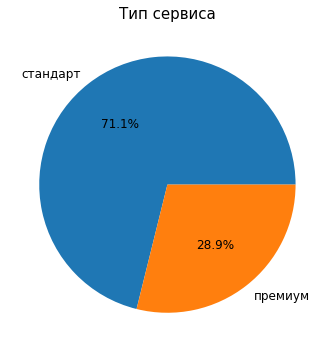

In [40]:
category_plot(users_data, ['Тип сервиса'])

#### Данные о выручке (market_money)

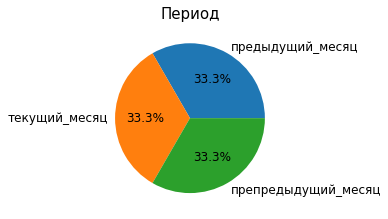

In [41]:
category_plot(revenue)

#### Данные о времени на сайте (market_time)

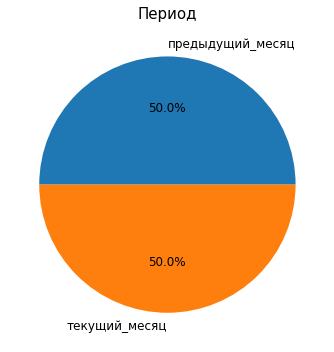

In [42]:
category_plot(timings)

### Отбор клиентов, активных в последние три месяца

In [43]:
revenue_pivot = revenue.pivot_table(
    index='id', 
    columns='Период', 
    values='Выручка'
).rename(columns={
    'текущий_месяц': 'текущий_месяц_уе',
    'предыдущий_месяц': 'предыдущий_месяц_уе',
    'препредыдущий_месяц': 'препредыдущий_месяц_уе',
})

In [44]:
revenue_pivot.head()

Период,предыдущий_месяц_уе,препредыдущий_месяц_уе,текущий_месяц_уе
id,,,
215348,0.0,0.0,3293.1
215349,5216.0,4472.0,4971.6
215350,5457.5,4826.0,5058.4
215351,6158.0,4793.0,6610.4
215352,5807.5,4594.0,5872.5


In [45]:
cols = ['текущий_месяц_уе', 'предыдущий_месяц_уе', 'препредыдущий_месяц_уе']

users_with_income_all_months = revenue_pivot[(revenue_pivot[cols] > 0).all(axis=1)]

In [46]:
users_with_income_all_months.head()

Период,предыдущий_месяц_уе,препредыдущий_месяц_уе,текущий_месяц_уе
id,,,
215349,5216.0,4472.0,4971.6
215350,5457.5,4826.0,5058.4
215351,6158.0,4793.0,6610.4
215352,5807.5,4594.0,5872.5
215353,4738.5,5124.0,5388.5


In [47]:
len(users_with_income_all_months.index.tolist())

1296

In [48]:
revenue_pivot.shape[0]

1299

Подведём итоги исследовательского анализа.

В данных нашлись и были исправлены две опечатки («предыдцщий_месяц» и «стандартт»), а клиента с id 215380 и аномально высокой выручкой мы удалили как выброс. Паттерн маркетинговых коммуникаций в текущем месяце отличается от среднемесячного за полгода: признак фактически принимает лишь несколько дискретных значений. По доле акционных покупок клиенты распадаются на два кластера: одни покупают преимущественно по акциям, другие пользуются акциями лишь при случае. Распределение времени на сайте в текущем месяце сместилось относительно предыдущего.

После отбора клиентов, покупавших во все три последних периода, осталось 1296 клиентов — почти вся выборка.

## Шаг 4. Объединение таблиц

Объединим market_file, market_money и market_time по id. Выручку и время на сайте развернём так, чтобы каждому периоду соответствовал отдельный столбец. Данные о прибыли из money.csv при моделировании нам не понадобятся — они пригодятся на этапе сегментации.

In [49]:
timings_pivot = timings.pivot_table(
    index='id', 
    columns='Период', 
    values='минут'
).rename(columns={
    'текущий_месяц': 'текущий_месяц_минуты',
    'предыдущий_месяц': 'предыдущий_месяц_минуты',
})

In [50]:
timings_pivot.head()

Период,предыдущий_месяц_минуты,текущий_месяц_минуты
id,,
215348,13,14
215349,12,10
215350,8,13
215351,11,13
215352,8,11


Проверим, есть ли у нас несовпадающие id клиентов в таблицах.

In [51]:
len(set(users_data['id']) ^ set(revenue['id']))

0

In [52]:
len(set(users_data['id']) ^ set(timings['id']))

0

In [53]:
len(set(users_data['id']) ^ set(avg_3m_profit['id']))

0

In [54]:
active_users = users_data[users_data['id'].isin(users_with_income_all_months.index)]

In [55]:
active_users.head()

,id,Покупательская активность,Тип сервиса,Разрешить сообщать,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Популярная_категория,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит
1,215349,Снизилась,премиум,да,4.4,4,819,0.75,Товары для детей,4,4,2,5
2,215350,Снизилась,стандарт,нет,4.9,3,539,0.14,Домашний текстиль,5,2,1,5
3,215351,Снизилась,стандарт,да,3.2,5,896,0.99,Товары для детей,5,0,6,4
4,215352,Снизилась,стандарт,нет,5.1,3,1064,0.94,Товары для детей,3,2,3,2
5,215353,Снизилась,стандарт,да,3.3,4,762,0.26,Домашний текстиль,4,1,1,4


In [56]:
full_data = pd.merge(active_users, revenue_pivot, on='id', how='inner')

In [57]:
full_data = pd.merge(full_data, timings_pivot, on='id', how='inner')

In [58]:
full_data.shape[0]

1296

In [59]:
full_data.head()

,id,Покупательская активность,Тип сервиса,Разрешить сообщать,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Популярная_категория,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит,предыдущий_месяц_уе,препредыдущий_месяц_уе,текущий_месяц_уе,предыдущий_месяц_минуты,текущий_месяц_минуты
0,215349,Снизилась,премиум,да,4.4,4,819,0.75,Товары для детей,4,4,2,5,5216.0,4472.0,4971.6,12,10
1,215350,Снизилась,стандарт,нет,4.9,3,539,0.14,Домашний текстиль,5,2,1,5,5457.5,4826.0,5058.4,8,13
2,215351,Снизилась,стандарт,да,3.2,5,896,0.99,Товары для детей,5,0,6,4,6158.0,4793.0,6610.4,11,13
3,215352,Снизилась,стандарт,нет,5.1,3,1064,0.94,Товары для детей,3,2,3,2,5807.5,4594.0,5872.5,8,11
4,215353,Снизилась,стандарт,да,3.3,4,762,0.26,Домашний текстиль,4,1,1,4,4738.5,5124.0,5388.5,10,10


In [60]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1296 entries, 0 to 1295
Data columns (total 18 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   id                                   1296 non-null   int64  
 1   Покупательская активность            1296 non-null   object 
 2   Тип сервиса                          1296 non-null   object 
 3   Разрешить сообщать                   1296 non-null   object 
 4   Маркет_актив_6_мес                   1296 non-null   float64
 5   Маркет_актив_тек_мес                 1296 non-null   int64  
 6   Длительность                         1296 non-null   int64  
 7   Акционные_покупки                    1296 non-null   float64
 8   Популярная_категория                 1296 non-null   object 
 9   Средний_просмотр_категорий_за_визит  1296 non-null   int64  
 10  Неоплаченные_продукты_штук_квартал   1296 non-null   int64  
 11  Ошибка_сервиса                

Итоговая таблица содержит 1296 активных клиентов, выручка и время на сайте разложены по отдельным столбцам для каждого периода. Пропусков после объединения не появилось: id во всех таблицах совпадают.

## Шаг 5. Корреляционный анализ

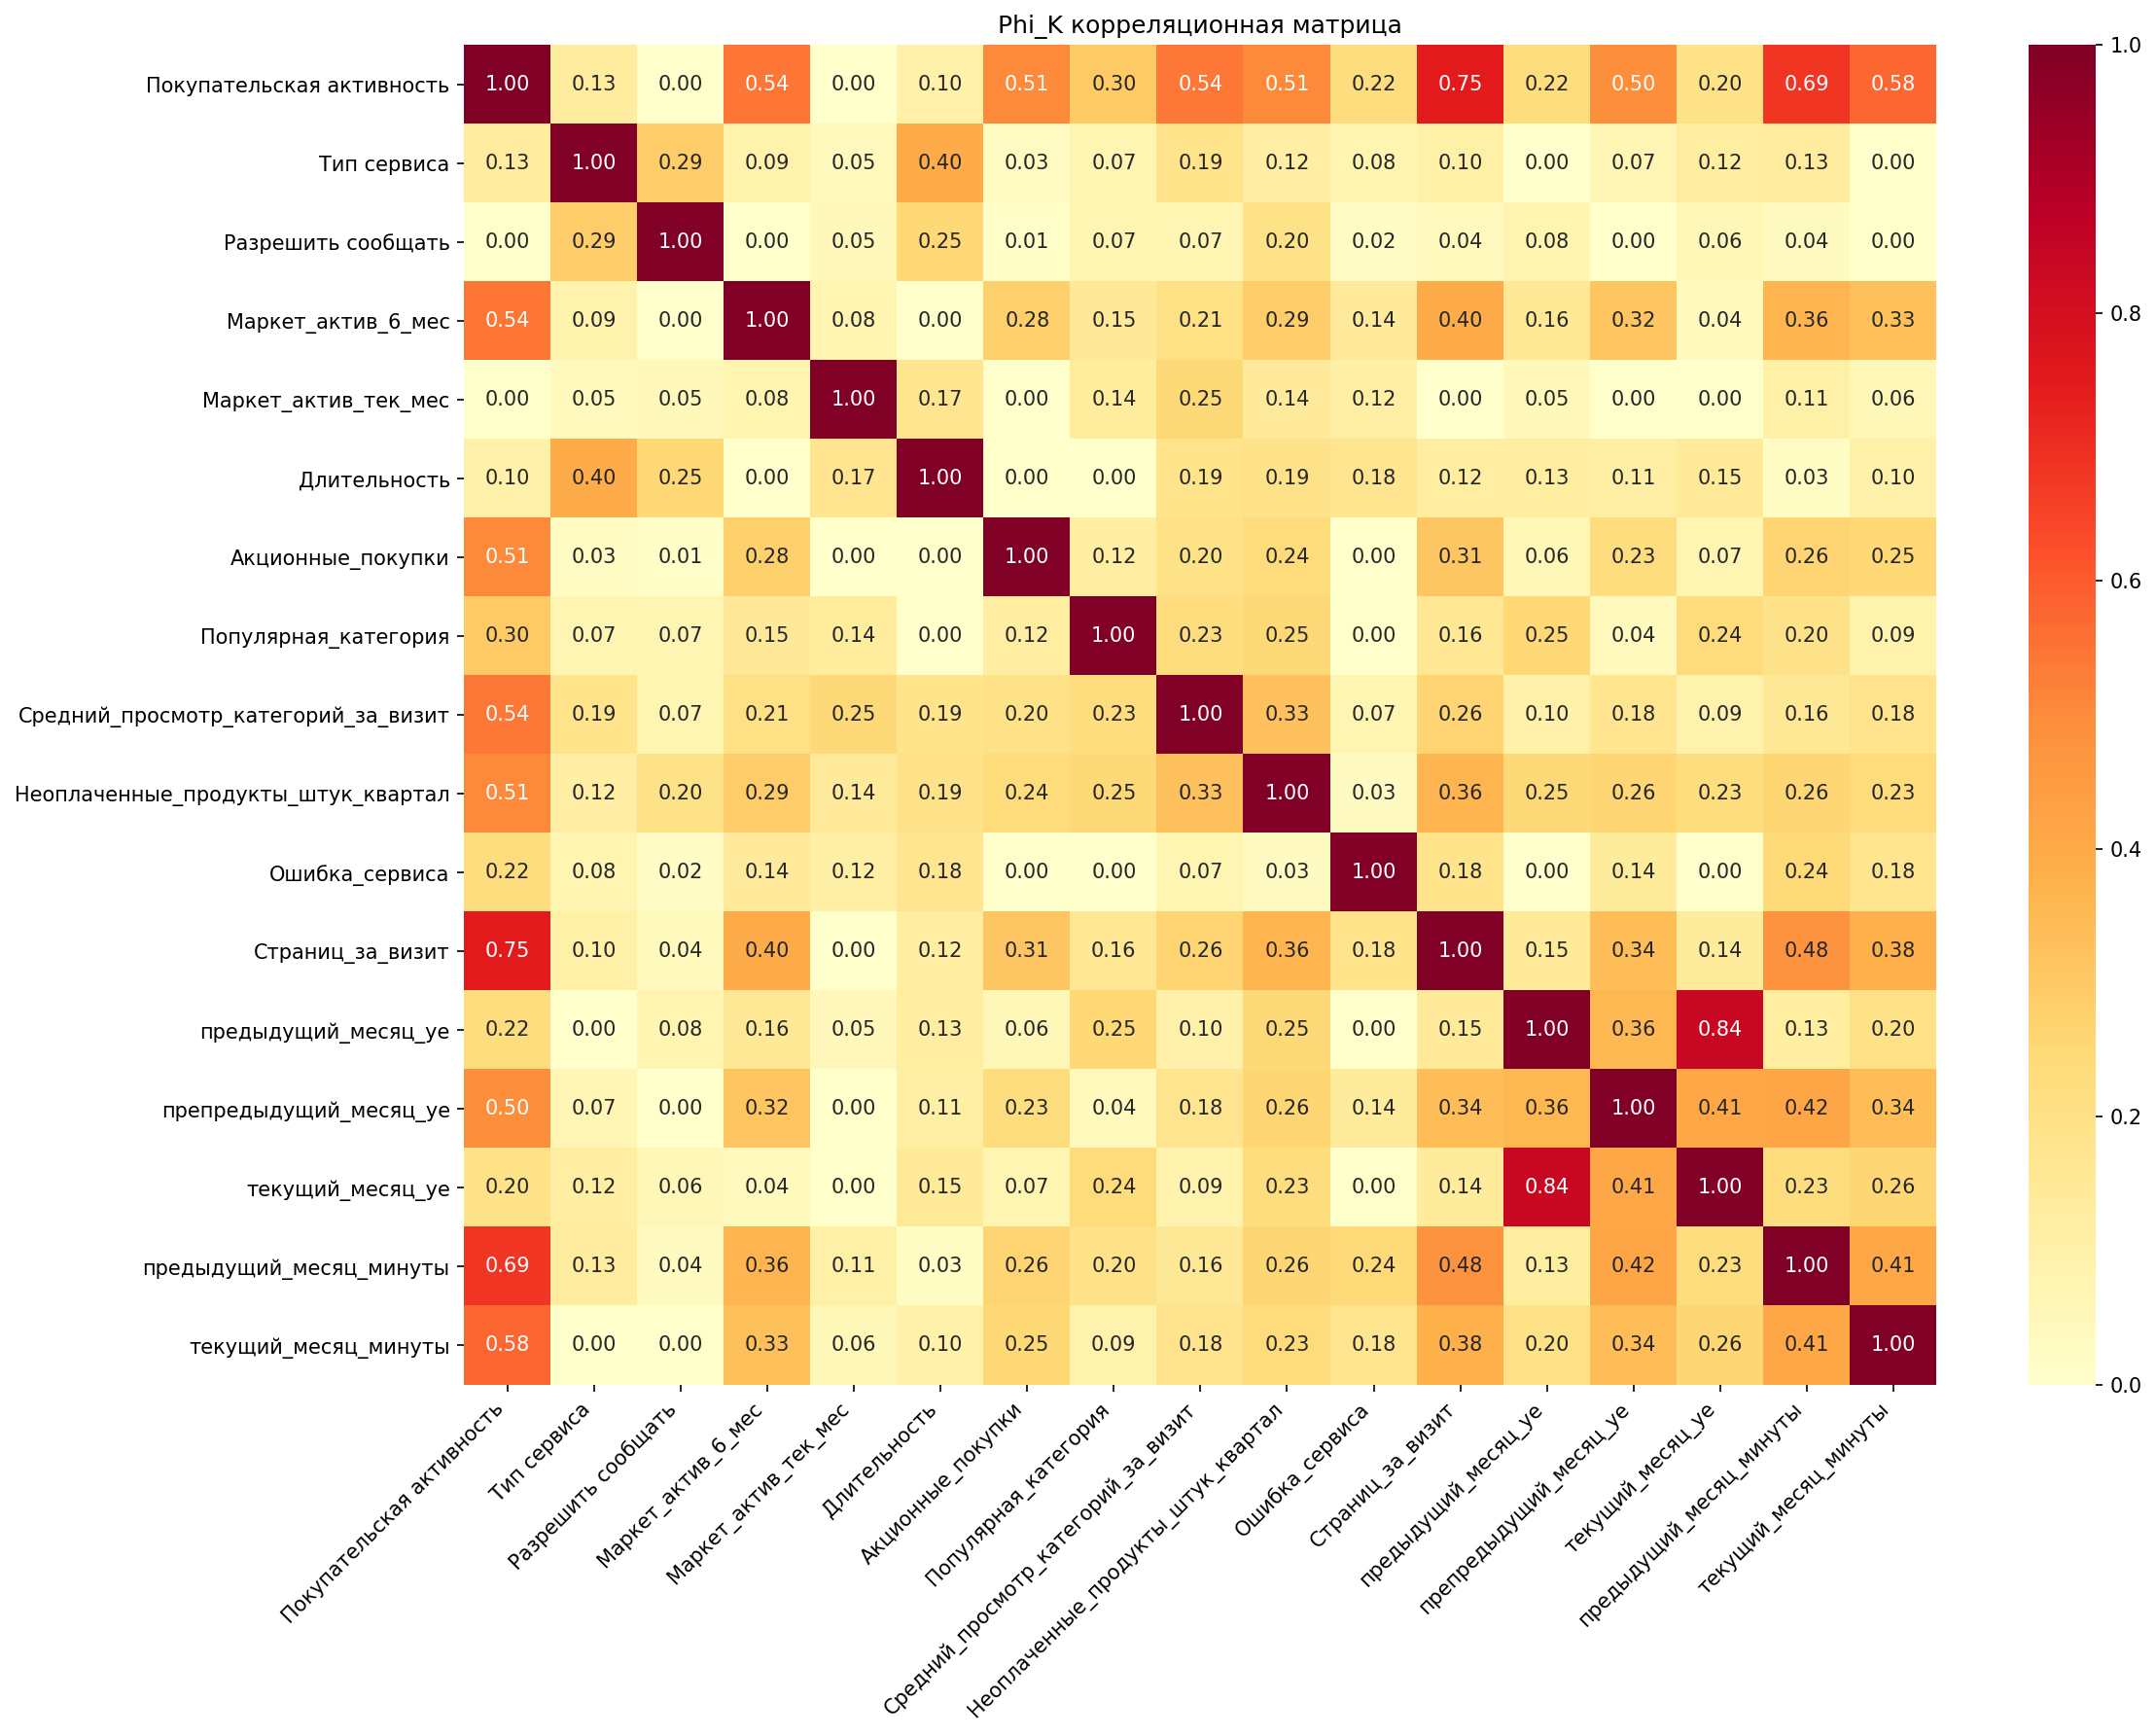

In [61]:
nice_heatmap(full_data)

Очевидный кандидат на мультиколлинеарность это параметры: "текущий месяц уе" и "предыдущий месяц уе". Но мы пока не будем их удалять, посмотрим, как на них отреагируют модели.

Так же надо учесть, что данный анализ выполнен по данным смешанных категорий.

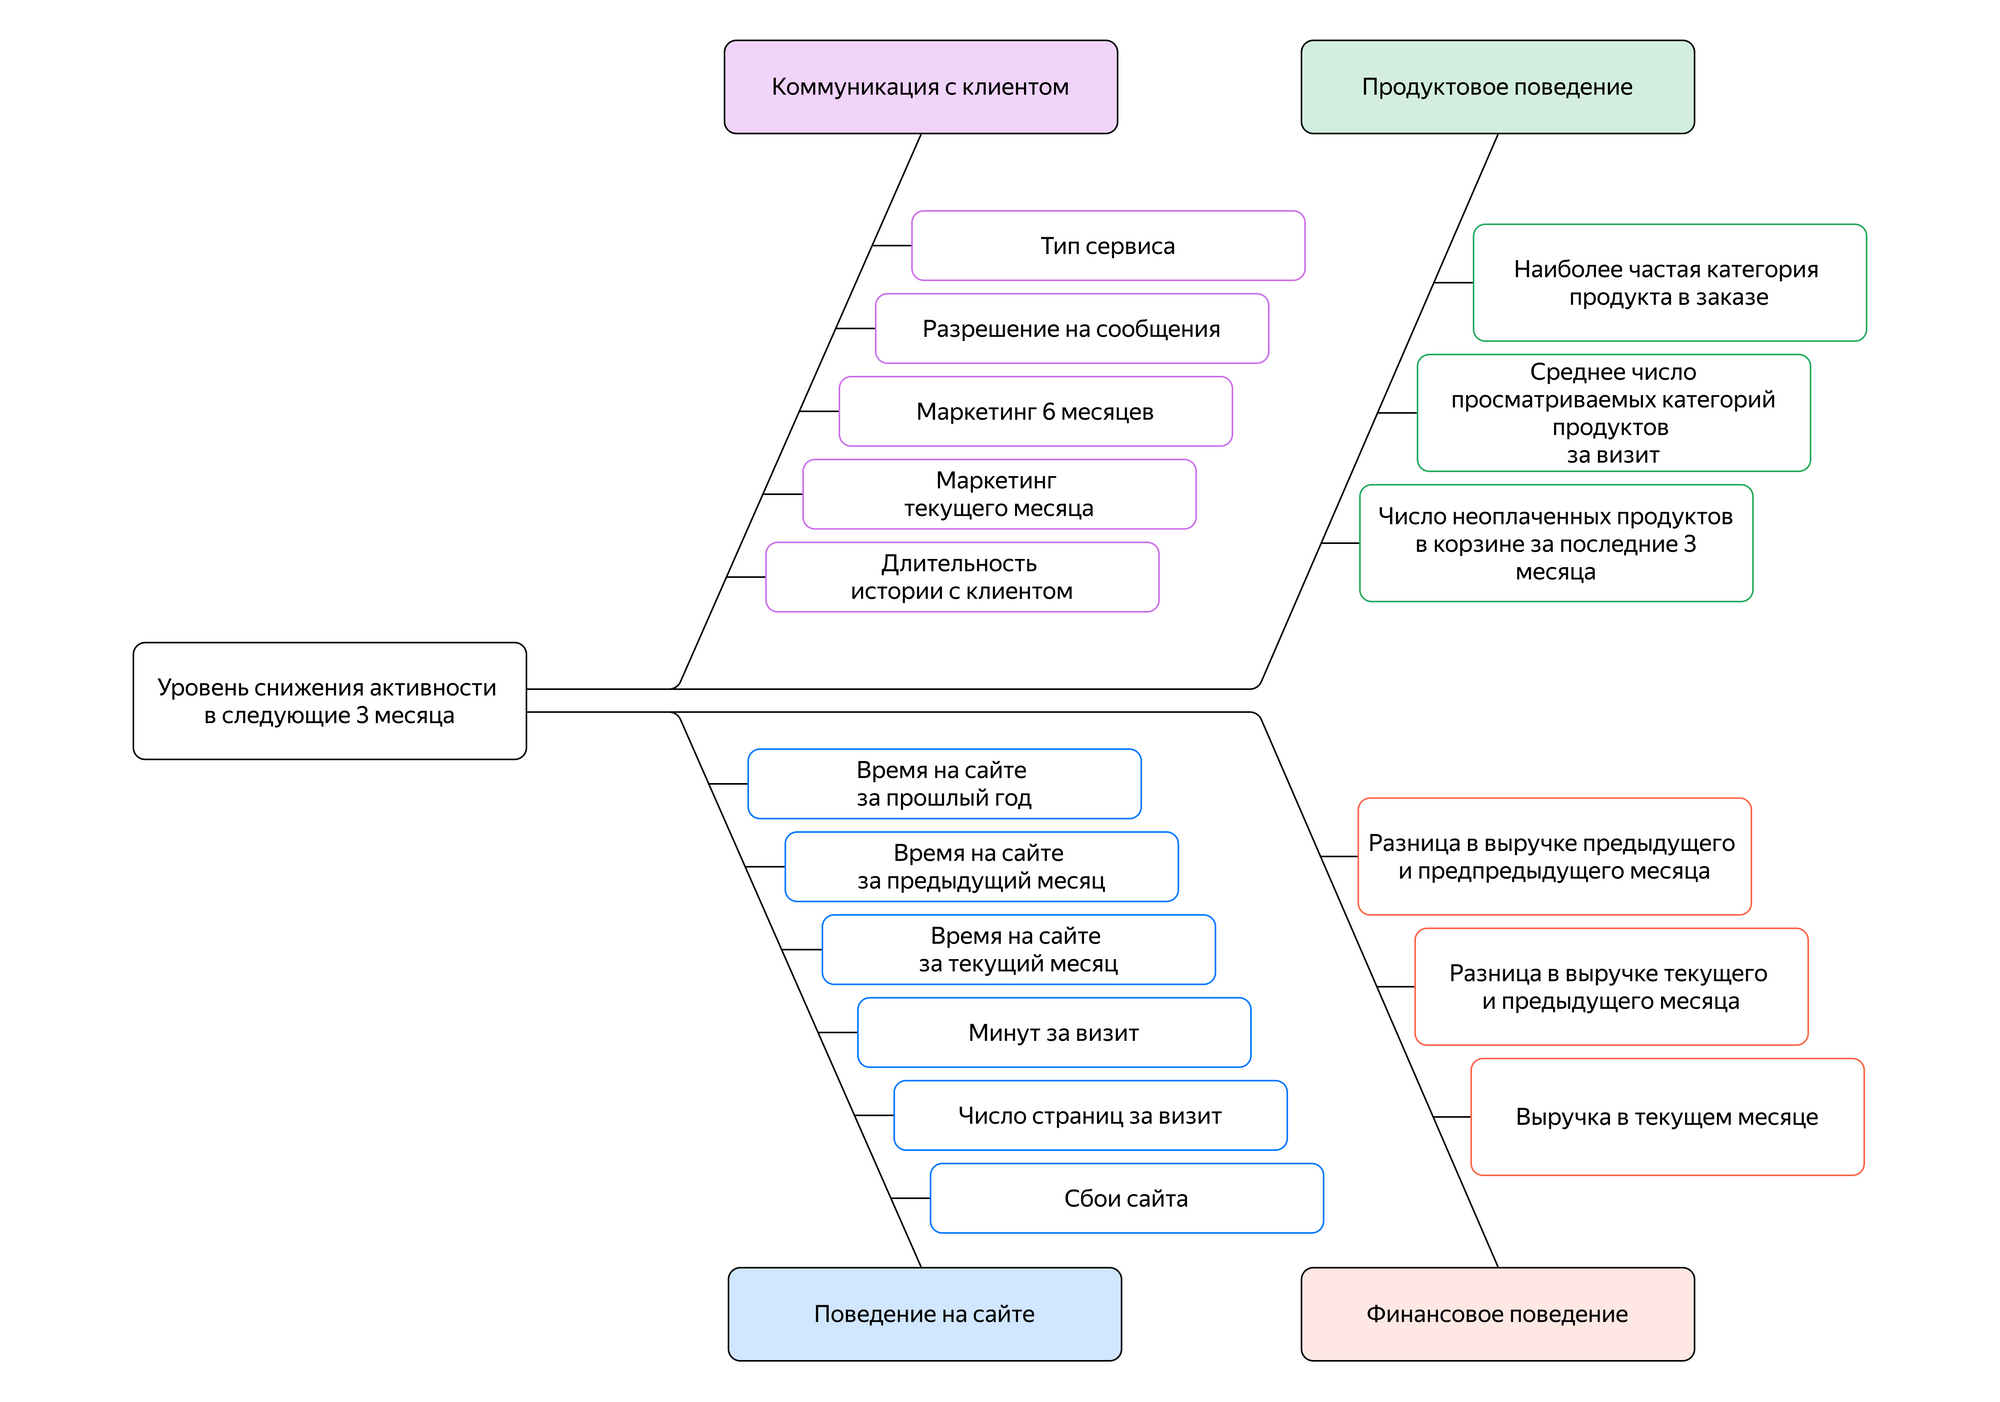

Построим корреляции для каждой категории отдельно. Выделим названия столбцов для каждой категории параметров в отдельные списки. 

In [62]:
communication_cols = [
    'Тип сервиса',
    'Разрешить сообщать',
    'Маркет_актив_6_мес',
    'Маркет_актив_тек_мес',
    'Длительность'
]

product_behavior_cols = [
    'Популярная_категория',
    'Средний_просмотр_категорий_за_визит',
    'Неоплаченные_продукты_штук_квартал',
    'Акционные_покупки'
]

site_behavior_cols = [
    'Страниц_за_визит',
    'Ошибка_сервиса',
    'предыдущий_месяц_минуты',
    'текущий_месяц_минуты'
]

financial_behavior_cols = [
    'препредыдущий_месяц_уе',
    'предыдущий_месяц_уе',
    'текущий_месяц_уе'
]

### Продуктовое поведение

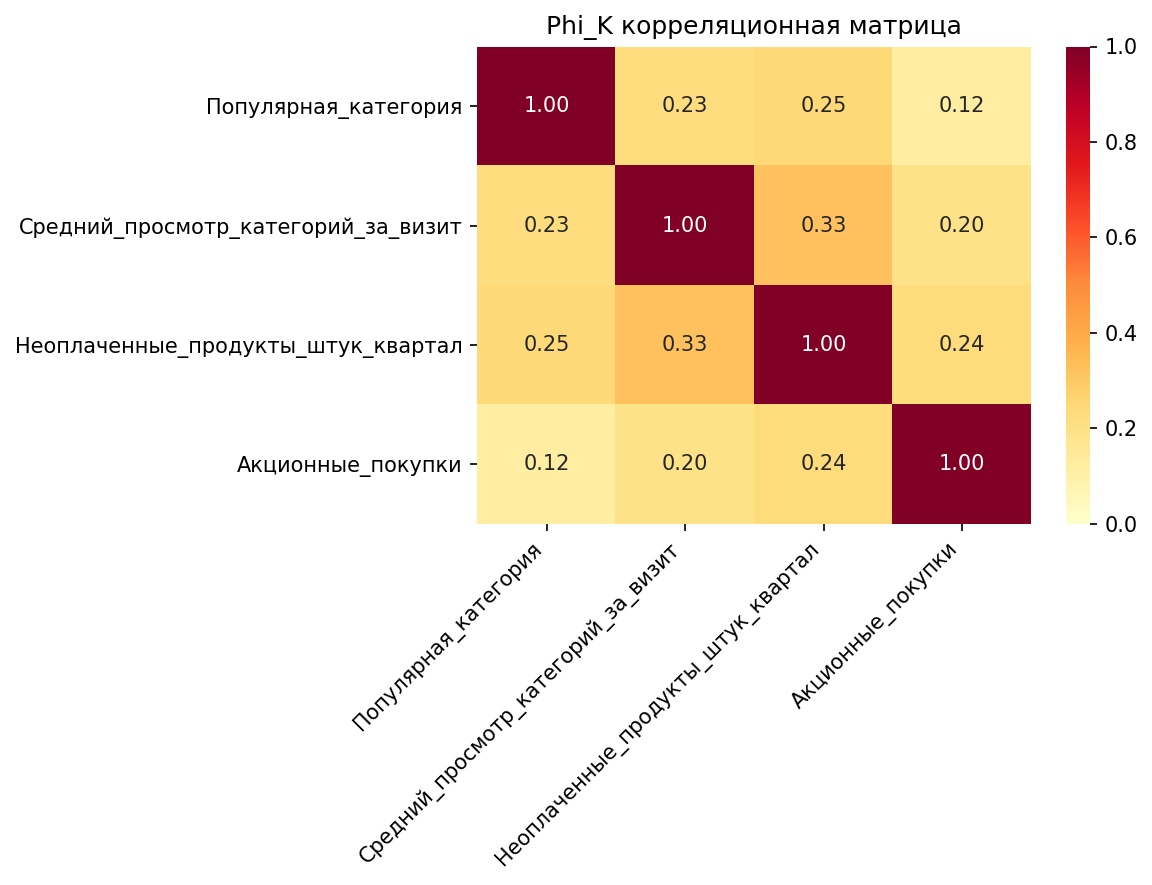

In [63]:
nice_heatmap(full_data[product_behavior_cols], figsize=(8, 6))

### Финансовое поведение

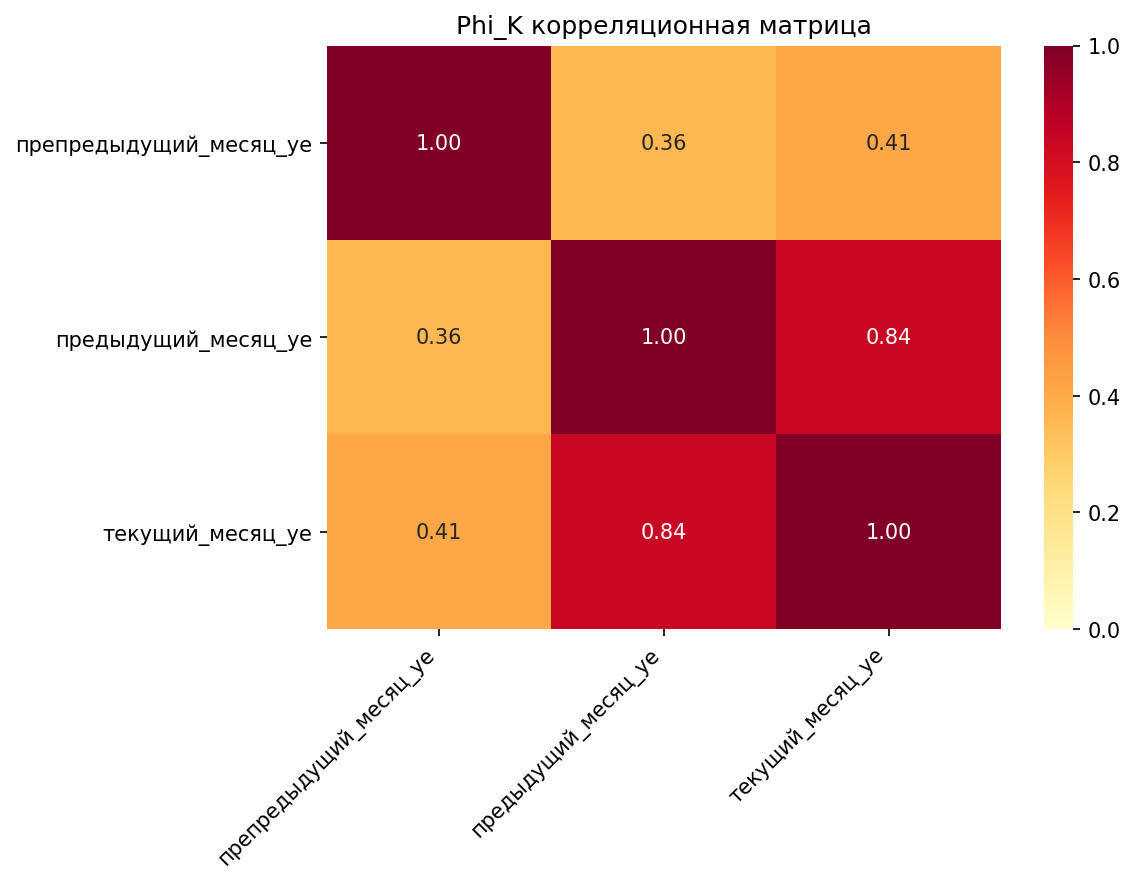

In [64]:
nice_heatmap(full_data[financial_behavior_cols], figsize=(8, 6))

### Поведение на сайте

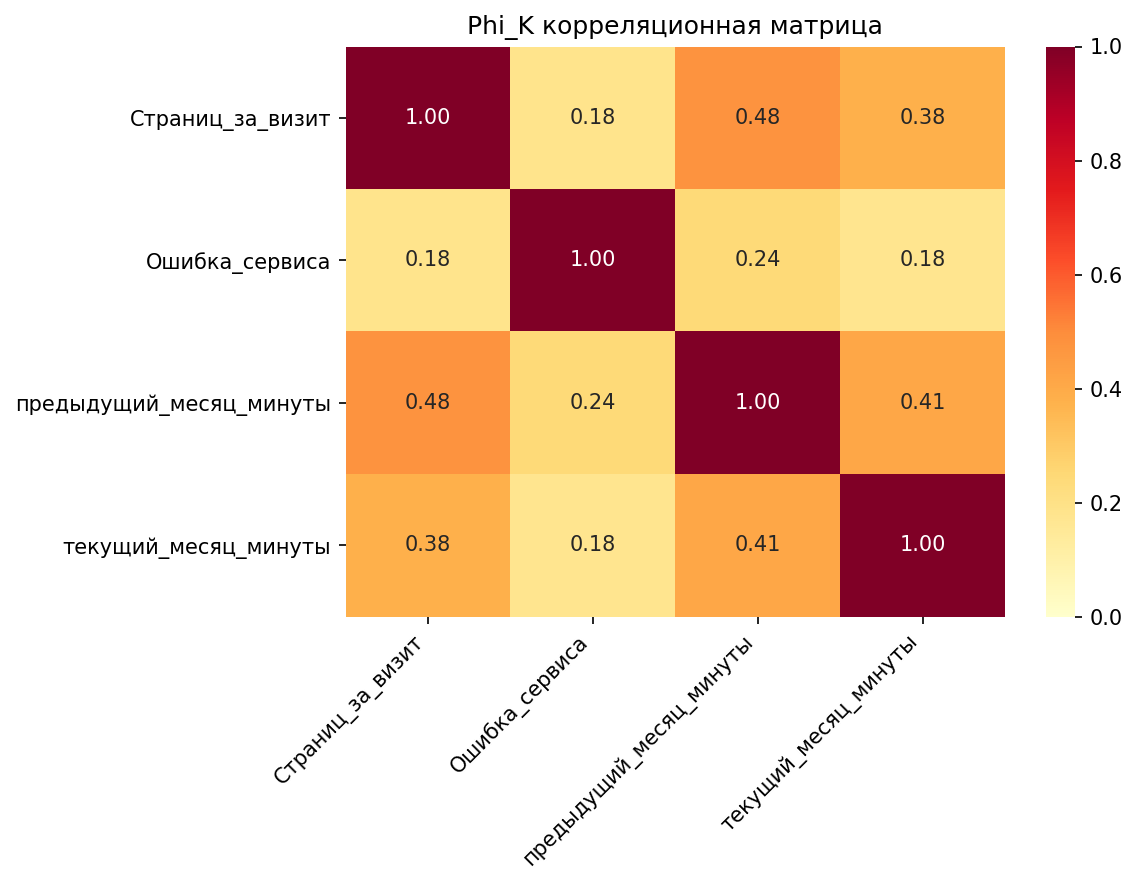

In [65]:
nice_heatmap(full_data[site_behavior_cols], figsize=(8, 6))

### Коммуникация с клиентом

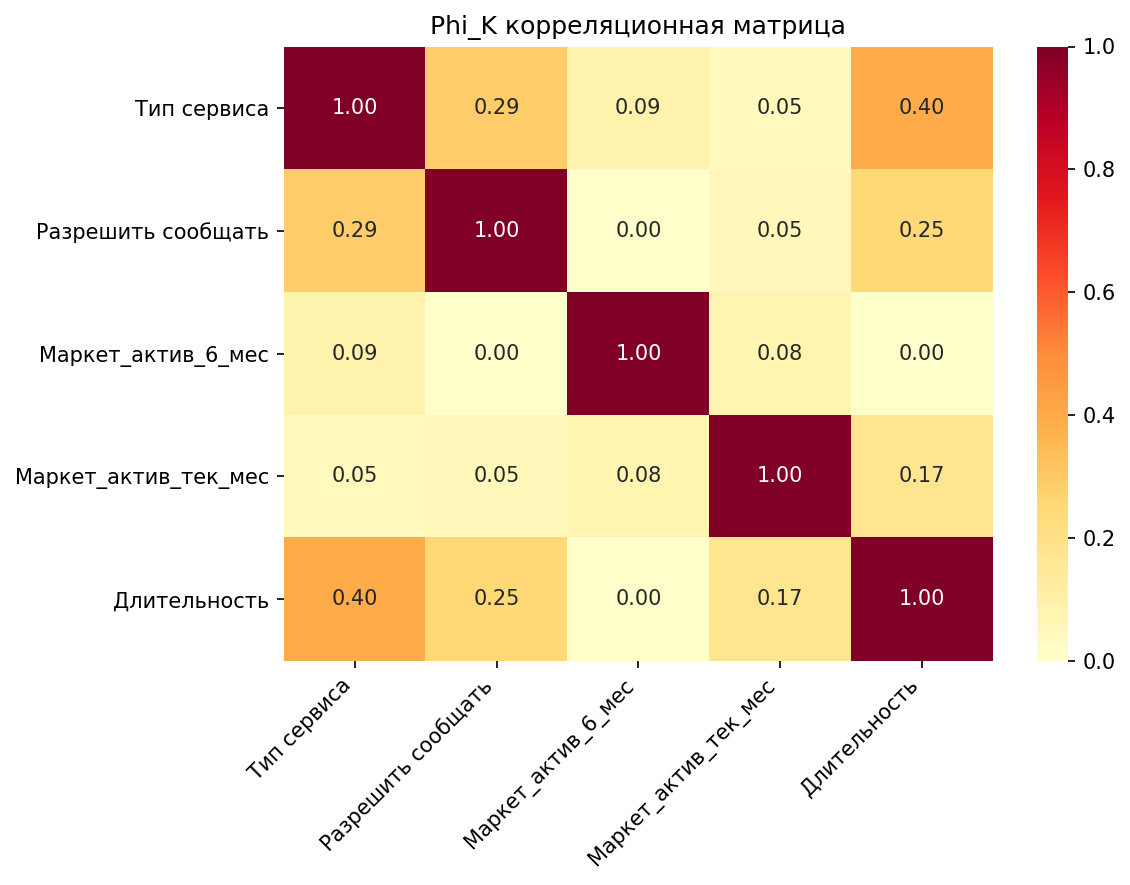

In [66]:
nice_heatmap(full_data[communication_cols], figsize=(8, 6))

С одной стороны, видна сильнейшая мультиколлинеарность между выручкой за текущий и предыдущий месяцы, с другой — если удалить один из этих признаков, мы потеряем треть информации о финансовом поведении пользователей. Пока оставим все признаки.

Часть моделей из нашего перебора умеет пессимизировать лишние признаки самостоятельно: дерево решений просто не делает сплиты по бесполезному признаку, а логистическая регрессия с L1-регуляризацией зануляет лишние коэффициенты. Но, например, SVC с ядром RBF так не умеет: в её метрике расстояния все признаки участвуют с одинаковым весом. Поэтому, если победит модель без механизма отбора признаков, мы вернёмся к этому решению и проверим его контрольным расчётом после выбора модели.

## Шаг 6. Пайплайны и выбор модели

### Подготовка данных

В наших данных отсутствуют пропуски, но, поскольку мы готовим инструмент для заказчика, который продолжет работу на его данных, надо предусмотреть наличие пропусков в них. Как следствие - в пайплайн предобработки добавим SimpleImputer.

Порядковых признаков в данных нет — только номинальные категориальные и количественные. По условию проекта используем два кодировщика категориальных признаков и два скейлера (StandardScaler и MinMaxScaler, плюс вариант без масштабирования). Кодировщик закрепим за типом модели: дереву решений — OrdinalEncoder, для него номера категорий лишь ярлыки, по которым удобно делать сплиты; а KNN, логистической регрессии и SVC — OneHotEncoder, потому что эти модели интерпретируют числа как величины, и порядок, который OrdinalEncoder присваивает категориям произвольно, исказил бы расстояния и коэффициенты. Скейлер для каждой модели выберет GridSearchCV.

In [67]:
categorial_cols = [
    'Тип сервиса',
    'Разрешить сообщать',
    'Популярная_категория',
]

numeric_cols = [
    'Маркет_актив_6_мес',
    'Маркет_актив_тек_мес',
    'Длительность',
    'Акционные_покупки',
    'Средний_просмотр_категорий_за_визит',
    'Неоплаченные_продукты_штук_квартал',
    'Ошибка_сервиса',
    'Страниц_за_визит',
    'предыдущий_месяц_уе',
    'препредыдущий_месяц_уе',
    'текущий_месяц_уе',
    'предыдущий_месяц_минуты',
    'текущий_месяц_минуты',
]

In [68]:
ohe_pipe = Pipeline(
    [
        (
            'simpleImputer_ohe',
            SimpleImputer(missing_values=np.nan, strategy='most_frequent'),
        ),
        (
            'ohe',
            OneHotEncoder(drop='first', sparse=False),
        )
    ]
)

oe_pipe = Pipeline(
    [
        (
            'simpleImputer_ord',
            SimpleImputer(missing_values=np.nan, strategy='most_frequent'),
        ),
        (
            'ord',
            OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
        )
    ]
)

In [69]:
num_pipe = Pipeline(
    [
        ('imputer', SimpleImputer(missing_values=np.nan, strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

data_preprocessor = ColumnTransformer(
    [
        ('cat', ohe_pipe, categorial_cols),
        ('num', num_pipe, numeric_cols),
    ],
    remainder = 'passthrough',
)

Создаём финальный пайплайн.

In [70]:
pipe_final = Pipeline(
    [
        ('preprocessor', data_preprocessor),
        ('models', DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]
)

In [71]:
param_grid = [
    {
        'models': [DecisionTreeClassifier(random_state=RANDOM_STATE)],
        'preprocessor__cat': [oe_pipe],
        'preprocessor__num__scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
    },
    {
        'models': [
            KNeighborsClassifier(),
            SVC(random_state=RANDOM_STATE),
            LogisticRegression(random_state=RANDOM_STATE, max_iter=10000),
            ],
        'preprocessor__cat': [ohe_pipe],
        'preprocessor__num__scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
    },
]

### Выбор метрики

Посмотрим на баланс классов целевого признака.

In [72]:
full_data['Покупательская активность'].value_counts(normalize=True).round(3)

Прежний уровень    0.619
Снизилась          0.381
Name: Покупательская активность, dtype: float64

Целевой признак умеренно несбалансирован: около 62 % клиентов сохранили активность, а 38 % — снизили. При этом бизнесу нужна не столько бинарная метка, сколько возможность ранжировать клиентов по риску: порог, начиная с которого клиенту делают персональное предложение, компания выберет позже, исходя из бюджета маркетинга.

Поэтому в качестве метрики мы возьмём ROC-AUC. Она оценивает качество ранжирования по вероятности и не зависит от выбранного порога классификации, а также устойчива к умеренному дисбалансу классов. Accuracy при дисбалансе давала бы завышенную оценку, а F1 потребовала бы зафиксировать порог и соотношение цены ошибок, которое бизнес пока не определил.

In [73]:
grid = GridSearchCV(
    pipe_final,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
)

### Разделение данных на выборки

Стратифицируем разбиение по целевому признаку, чтобы доли классов в обучающей и тестовой выборках совпадали.

In [74]:
X = full_data.drop(['Покупательская активность', 'id'], axis=1)
y = full_data['Покупательская активность']

In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

In [76]:
pipe_final.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  Pipeline(steps=[('simpleImputer_ohe',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(drop='first',
                                                                                 sparse=False))]),
                                                  ['Тип сервиса',
                                                   'Разрешить сообщать',
                                                   'Популярная_категория']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                  

In [77]:
grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('cat',
                                                                         Pipeline(steps=[('simpleImputer_ohe',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('ohe',
                                                                                          OneHotEncoder(drop='first',
                                                                                                        sparse=False))]),
                                                                         ['Тип '
                                                                          'сервиса',
                

In [78]:
print('Лучшая модель и её параметры: ', grid.best_estimator_)

Лучшая модель и её параметры:  Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  Pipeline(steps=[('simpleImputer_ohe',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(drop='first',
                                                                                 sparse=False))]),
                                                  ['Тип сервиса',
                                                   'Разрешить сообщать',
                                                   'Популярная_категория']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
   

In [79]:
print('Метрика ROC-AUC для лучшей модели:\n', grid.best_score_) 

Метрика ROC-AUC для лучшей модели:
 0.9083356265356265


Уже с гиперпараметрами по умолчанию лучший результат показывает SVC. Теперь подберём гиперпараметры для каждой модели.

### Подбор гиперпараметров

Для каждой из четырёх моделей подберём гиперпараметры, а заодно дадим GridSearchCV выбрать кодировщик категориальных признаков и скейлер.

In [80]:
param_grid = [
    {
        'models': [DecisionTreeClassifier(random_state=RANDOM_STATE)],
        'models__max_depth': range(2, 5),
        'models__max_features': range(2, 5),
        'preprocessor__cat': [oe_pipe],
        'preprocessor__num__scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
    },
    {
        'models': [KNeighborsClassifier()],
        'models__n_neighbors': range(2, 5),
        'preprocessor__cat': [ohe_pipe],
        'preprocessor__num__scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
    },
    {
        'models': [LogisticRegression(
            random_state=RANDOM_STATE,
            solver='liblinear',
            penalty='l1',
            max_iter=10000,
        )],
        'models__C': range(1, 5),
        'preprocessor__cat': [ohe_pipe],
        'preprocessor__num__scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
    },
    {
        'models': [SVC(random_state=RANDOM_STATE)],
        'models__C': [0.01, 0.1, 1, 10, 100],
        'models__gamma': ['scale', 0.001, 0.01, 0.1, 1],
        'preprocessor__cat': [ohe_pipe],
        'preprocessor__num__scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
    },
]

In [81]:
grid = GridSearchCV(
    pipe_final,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
)

In [82]:
grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('cat',
                                                                         Pipeline(steps=[('simpleImputer_ohe',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('ohe',
                                                                                          OneHotEncoder(drop='first',
                                                                                                        sparse=False))]),
                                                                         ['Тип '
                                                                          'сервиса',
                

In [83]:
print('Лучшая модель и её параметры: ', grid.best_estimator_)
print()
print('Лучший кодировщик категориальных признаков:',
      grid.best_params_['preprocessor__cat'].steps[-1][1].__class__.__name__)
print('Лучший скейлер количественных признаков:',
      grid.best_params_['preprocessor__num__scaler'])

Лучшая модель и её параметры:  Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  Pipeline(steps=[('simpleImputer_ohe',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(drop='first',
                                                                                 sparse=False))]),
                                                  ['Тип сервиса',
                                                   'Разрешить сообщать',
                                                   'Популярная_категория']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
   

In [84]:
print('Метрика ROC-AUC для лучшей модели:\n', grid.best_score_) 

Метрика ROC-AUC для лучшей модели:
 0.9121031072394707


### Проверка лучшей модели на тестовой выборке

SVC по умолчанию не возвращает вероятности, поэтому для расчёта ROC-AUC используем значения решающей функции `decision_function` — для ранжирования клиентов по риску этого достаточно.

In [85]:
champion = grid.best_estimator_

In [86]:
y_scores = champion.decision_function(X_test)

In [87]:
roc_auc = roc_auc_score(y_test, y_scores)

In [88]:
print(f'ROC-AUC на тесте: {roc_auc:.4f}')

ROC-AUC на тесте: 0.9112


ROC-AUC на тестовой выборке (0.911) практически совпадает с кросс-валидацией (0.912) — модель не переобучилась.

Подведём итог шага. С помощью единого пайплайна и GridSearchCV мы перебрали четыре модели (KNN, дерево решений, логистическая регрессия и SVC) с их гиперпараметрами, два скейлера (StandardScaler и MinMaxScaler) и вариант без масштабирования; кодировщик категориальных признаков был закреплён за типом модели — OrdinalEncoder у дерева, OneHotEncoder у остальных. Лучшей оказалась модель SVC (C=0.1, gamma=0.1) в связке с OneHotEncoder и StandardScaler. Ядро у неё RBF: это значение kernel по умолчанию, в сетке гиперпараметров мы перебирали только C и gamma. Итог: ROC-AUC получилась около 0.912 на кросс-валидации и 0.911 на тесте.

### Контрольная проверка решения шага 5

В шаге 5 мы оставили сильно коррелирующие выручку текущего и предыдущего месяцев в расчёте на то, что модели пессимизируют лишнее сами. Победила SVC с ядром RBF, которая этого не умеет, поэтому проверим решение явно: сравним кросс-валидационную ROC-AUC победившего пайплайна на полном наборе признаков и без каждого из «близнецов».

In [89]:
best_cat = champion.named_steps['preprocessor'].named_transformers_['cat']
best_num = champion.named_steps['preprocessor'].named_transformers_['num']
best_model = champion.named_steps['models']

feature_sets = {
    'все признаки': [],
    'без текущий_месяц_уе': ['текущий_месяц_уе'],
    'без предыдущий_месяц_уе': ['предыдущий_месяц_уе'],
    'без обоих признаков': ['текущий_месяц_уе', 'предыдущий_месяц_уе'],
}

for name, excluded in feature_sets.items():
    cols = [c for c in numeric_cols if c not in excluded]
    pipe = Pipeline([
        ('preprocessor', ColumnTransformer([
            ('cat', clone(best_cat), categorial_cols),
            ('num', clone(best_num), cols),
        ])),
        ('models', clone(best_model)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='roc_auc', n_jobs=-1)
    print(f'{name:32} ROC-AUC = {scores.mean():.4f} +/- {scores.std():.4f}')

все признаки                     ROC-AUC = 0.9121 +/- 0.0138
без текущий_месяц_уе             ROC-AUC = 0.9133 +/- 0.0129
без предыдущий_месяц_уе          ROC-AUC = 0.9131 +/- 0.0142
без обоих признаков              ROC-AUC = 0.9149 +/- 0.0149


Все различия лежат в пределах разброса между фолдами (около ±0.014), то есть статистически незначимы, но знак стал любопытным: без каждого из «близнецов» кросс-валидационная метрика даже чуть выше, а без обоих — выше всего. То есть дублирующая пара модели точно не помогает. Менять набор признаков после проверки модели на тесте мы уже не будем, чтобы не подгонять решение под результат, но при развитии модели выручка текущего и предыдущего месяцев — первые кандидаты на удаление.

Отметим, что к SHAP-значимостям коррелирующей пары в следующем шаге стоит относиться с оговоркой: SHAP делит вклад между такими признаками, поэтому их индивидуальные значимости занижены.

## Шаг 7. Анализ важности признаков

Лучшая модель — SVC с ядром RBF. Это нелинейная модель, у которой нет встроенной оценки важности признаков, поэтому оценим важность методом SHAP. Знакомый нам LinearExplainer здесь не подойдёт: он считает SHAP-значения аналитически из коэффициентов линейной модели, а у SVC с ядром RBF коэффициентов в пространстве признаков не существует. Поэтому возьмём модельно-независимый KernelExplainer: ему нужны только функция предсказания и фоновая выборка, взамен он работает медленнее и оценивает SHAP-значения приближённо.

Объяснять будем значение решающей функции на предобработанных признаках: положительные SHAP-значения сдвигают предсказание в сторону класса «Снизилась». Чтобы расчёт не занял слишком много времени, в качестве фоновой выборки возьмём 25 центров кластеров обучающей выборки, а объяснять будем 100 случайных объектов тестовой выборки.

In [90]:
preprocessor = champion.named_steps['preprocessor']
model = champion.named_steps['models']

cat_encoder = preprocessor.named_transformers_['cat'].steps[-1][1]
if hasattr(cat_encoder, 'get_feature_names'):
    cat_feature_names = list(cat_encoder.get_feature_names(categorial_cols))
else:
    cat_feature_names = list(categorial_cols)

feature_names = cat_feature_names + numeric_cols

X_train_prep = pd.DataFrame(
    preprocessor.transform(X_train),
    columns=feature_names,
    index=X_train.index,
)
X_test_prep = pd.DataFrame(
    preprocessor.transform(X_test),
    columns=feature_names,
    index=X_test.index,
)
X_test_prep.head()

,Тип сервиса_стандарт,Разрешить сообщать_нет,Популярная_категория_Косметика и аксесуары,Популярная_категория_Кухонная посуда,Популярная_категория_Мелкая бытовая техника и электроника,Популярная_категория_Техника для красоты и здоровья,Популярная_категория_Товары для детей,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит,предыдущий_месяц_уе,препредыдущий_месяц_уе,текущий_месяц_уе,предыдущий_месяц_минуты,текущий_месяц_минуты
809,1.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.169629,-0.034940,-0.003856,-0.678649,2.045527,-0.927589,-0.099707,0.961202,-1.405144,0.214194,-2.320463,0.624051,0.894668
302,0.0,1.0,0.0,0.0,0.0,0.0,1.0,-2.866015,-0.034940,0.307182,2.517826,-0.183455,1.542593,-1.646221,-0.557143,-2.013227,-0.540665,-1.271572,-0.647600,-1.024488
955,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.968558,-0.034940,-0.474402,-0.759573,0.559539,-0.433553,1.962313,0.455087,0.699537,-0.808993,1.304666,1.641373,-0.544699
149,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.768826,-1.450017,1.794585,0.130585,0.559539,0.060484,0.415798,-0.557143,2.359246,0.453036,1.807872,-1.156261,-1.024488
582,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.228498,-0.034940,-1.834199,2.720134,-1.669444,-0.433553,-0.615212,-0.304085,0.193040,-1.145141,0.635946,0.369721,1.134563


In [91]:
background = shap.kmeans(X_train_prep, 25)
X_shap = X_test_prep.sample(100, random_state=RANDOM_STATE)

explainer = shap.KernelExplainer(model.decision_function, background)
shap_values = explainer.shap_values(X_shap, nsamples=100)

  0%|          | 0/100 [00:00<?, ?it/s]

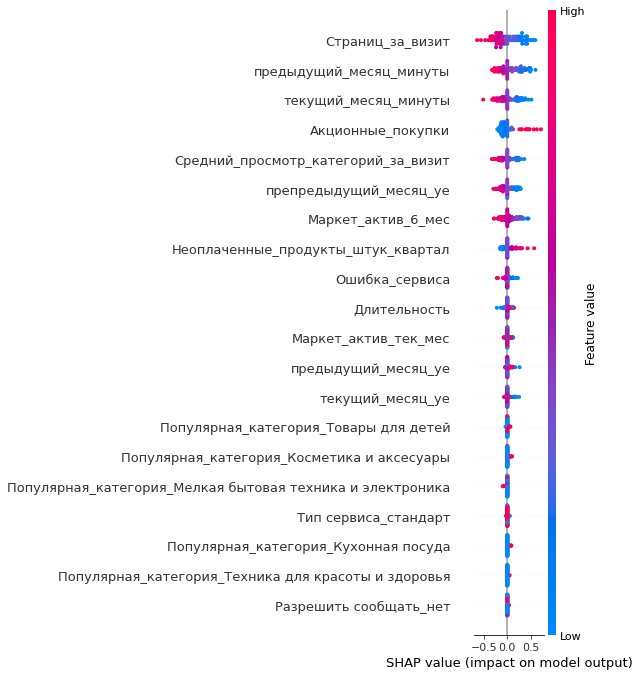

In [92]:
shap.summary_plot(shap_values, X_shap)

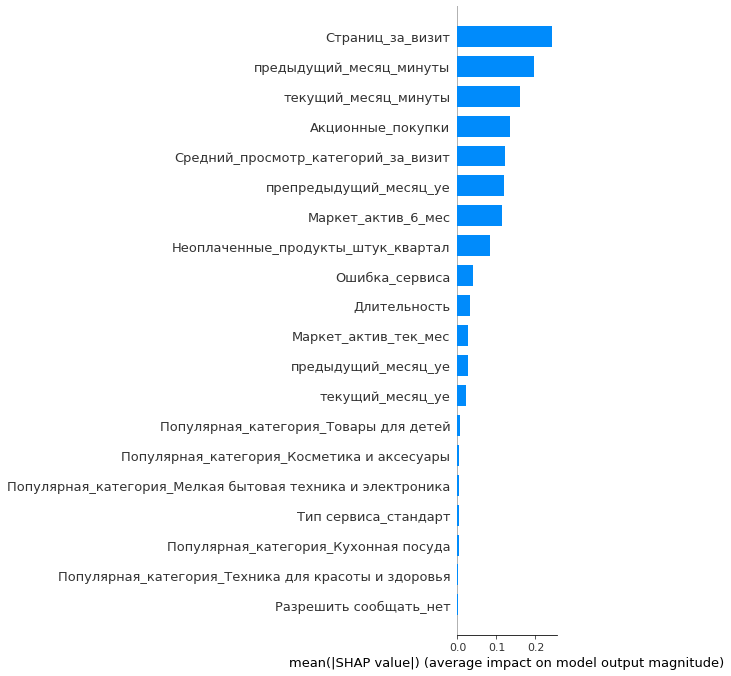

In [93]:
shap.summary_plot(shap_values, X_shap, plot_type='bar')

In [94]:
shap_importance = pd.Series(
    np.abs(shap_values).mean(axis=0), index=X_shap.columns
).sort_values(ascending=False)
shap_importance.round(3)

Страниц_за_визит                                             0.242
предыдущий_месяц_минуты                                      0.196
текущий_месяц_минуты                                         0.161
Акционные_покупки                                            0.134
Средний_просмотр_категорий_за_визит                          0.122
препредыдущий_месяц_уе                                       0.119
Маркет_актив_6_мес                                           0.115
Неоплаченные_продукты_штук_квартал                           0.084
Ошибка_сервиса                                               0.041
Длительность                                                 0.032
Маркет_актив_тек_мес                                         0.028
предыдущий_месяц_уе                                          0.027
текущий_месяц_уе                                             0.022
Популярная_категория_Товары для детей                        0.006
Популярная_категория_Косметика и аксесуары                   0

Сильнее всего на предсказание влияют признаки, описывающие вовлечённость клиента. Самый важный — число страниц за визит: чем меньше страниц просматривает клиент, тем выше вероятность снижения активности. Следом идут время на сайте в предыдущем и текущем месяцах, доля акционных покупок и среднее число просмотренных категорий; из финансовых признаков заметен вклад выручки за препредыдущий месяц, рядом с ним — маркетинговая активность за полгода.

После One-Hot-кодирования категориальные признаки развернулись в отдельные бинарные столбцы вида «Популярная_категория_Товары для детей» — и все они оказались в самом хвосте рейтинга: вклад каждой категории не превышает 0.007. Малозначимы для модели также разрешение сообщать, тип сервиса, длительность, маркетинговая активность текущего месяца и выручка текущего и предыдущего месяцев.

Эти наблюдения можно использовать двояко. При моделировании малозначимые признаки — кандидаты на удаление: более компактная модель проще в поддержке и требует меньше данных от заказчика, но прежде чем убирать признаки, стоит проверить, что качество без них не падает. Для бизнеса же главный маркер риска — не деньги, а падение вовлечённости: клиент сначала начинает реже и «мельче» ходить по сайту и лишь потом меньше покупать. Наблюдая за числом страниц, временем на сайте и просматриваемыми категориями, можно заметить «остывающего» клиента раньше, чем упадут покупки. Второй маркер риска — высокая зависимость покупок от акций.

### Перестановочная важность признаков

Дополнительно оценим важность признаков вторым методом из курса — перестановочным (permutation importance). Идея простая: перемешиваем значения одного признака по всем клиентам тестовой выборки, разрушая его связь с целевым признаком, и смотрим, насколько упадёт ROC-AUC; чем сильнее падение, тем важнее признак. Метод, как и SHAP, модельно-независимый — ему нужны только обученная модель и метрика.

В отличие от SHAP перемешивание происходит на входе всего пайплайна, поэтому важности получаются для исходных признаков до кодирования и масштабирования.

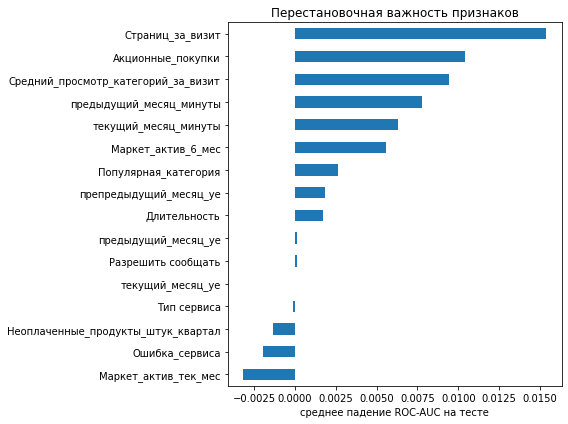

In [95]:
perm = permutation_importance(
    champion,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

perm_importance = pd.Series(perm.importances_mean, index=X_test.columns)

plt.figure(figsize=(8, 6))
perm_importance.sort_values().plot(kind='barh')
plt.title('Перестановочная важность признаков')
plt.xlabel('среднее падение ROC-AUC на тесте')
plt.tight_layout()
plt.show()

In [96]:
perm_importance.sort_values(ascending=False).round(4)

Страниц_за_визит                       0.0154
Акционные_покупки                      0.0104
Средний_просмотр_категорий_за_визит    0.0094
предыдущий_месяц_минуты                0.0078
текущий_месяц_минуты                   0.0063
Маркет_актив_6_мес                     0.0056
Популярная_категория                   0.0026
препредыдущий_месяц_уе                 0.0018
Длительность                           0.0017
предыдущий_месяц_уе                    0.0001
Разрешить сообщать                     0.0001
текущий_месяц_уе                      -0.0000
Тип сервиса                           -0.0001
Неоплаченные_продукты_штук_квартал    -0.0013
Ошибка_сервиса                        -0.0019
Маркет_актив_тек_мес                  -0.0032
dtype: float64

Оба метода согласны в главном. Лидер тот же — число страниц за визит: его перемешивание роняет ROC-AUC на 0.015, в полтора раза сильнее ближайшего преследователя. Дальше снова признаки вовлечённости — доля акционных покупок, просмотренные категории и время на сайте. В хвосте тоже совпадение: тип сервиса, разрешение сообщать, выручка текущего и предыдущего месяцев моделью почти не используются, а у нескольких признаков перестановочные важности даже слегка отрицательные. Это шум: перемешивание бесполезного признака может случайно «улучшить» метрику, у действительно важного признака такого не бывает.

Есть и расхождения. Популярная категория здесь единый признак — перемешиваются исходные столбцы до кодирования, — и её важность невелика, что согласуется с хвостовыми позициями её категорий в SHAP. А вот число неоплаченных товаров и число сбоев сервиса SHAP считает умеренно полезными, тогда как перестановочный метод — бесполезными. Это нормально: методы отвечают на разные вопросы — SHAP показывает, как признак сдвигает конкретные предсказания, а перестановка — насколько от признака зависит метрика на тесте. К тому же важность коррелирующих признаков оба метода делят между «близнецами».

Практический вывод у обоих методов один: за риском снижения активности надо следить в первую очередь по вовлечённости клиента на сайте.

## Шаг 8. Сегментация покупателей

Получим для каждого активного клиента вероятность снижения активности и объединим её с данными о среднемесячной прибыли из money.csv.

Для дополнительного исследования возьмём сегмент клиентов с высокой вероятностью снижения активности и высокой прибыльностью: их потеря обойдётся компании дороже всего, поэтому удерживать их нужно в первую очередь.

SVC по умолчанию не считает вероятности, поэтому переобучим лучшую модель с параметром probability=True.

In [97]:
champion_proba = clone(champion)
champion_proba.set_params(models__probability=True)
champion_proba.fit(X_train, y_train)

class_idx = list(champion_proba.classes_).index('Снизилась')

In [98]:
segmentation = full_data[['id']].copy()
segmentation['вероятность_снижения'] = champion_proba.predict_proba(X)[:, class_idx]
segmentation = segmentation.merge(avg_3m_profit, on='id', how='left')
segmentation.describe()

,id,вероятность_снижения,Прибыль
count,1296.000000,1296.000000,1296.000000
mean,215999.464506,0.380753,3.997701
std,374.327860,0.382799,1.011198
min,215349.000000,0.007611,0.860000
25%,215675.750000,0.067728,3.300000
50%,215999.500000,0.153684,4.045000
75%,216323.250000,0.876913,4.670000
max,216647.000000,0.997212,7.430000


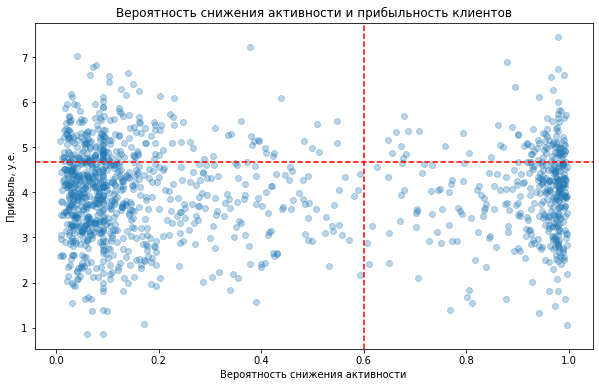

In [99]:
PROB_THRESHOLD = 0.6
profit_threshold = segmentation['Прибыль'].quantile(0.75)

plt.figure(figsize=(10, 6))
plt.scatter(
    segmentation['вероятность_снижения'],
    segmentation['Прибыль'],
    alpha=0.3,
)
plt.axvline(PROB_THRESHOLD, color='red', linestyle='--')
plt.axhline(profit_threshold, color='red', linestyle='--')
plt.xlabel('Вероятность снижения активности')
plt.ylabel('Прибыль, у.е.')
plt.title('Вероятность снижения активности и прибыльность клиентов')
plt.show()

В правом верхнем углу графика — целевой сегмент: вероятность снижения активности не ниже 0.6 и прибыль в верхнем квартиле (не ниже 75-го перцентиля).

In [100]:
full_seg = full_data.merge(
    segmentation[['id', 'вероятность_снижения', 'Прибыль']], on='id'
)
full_seg['сегмент'] = np.where(
    (full_seg['вероятность_снижения'] >= PROB_THRESHOLD)
    & (full_seg['Прибыль'] >= profit_threshold),
    'риск + высокая прибыль',
    'остальные',
)
full_seg['сегмент'].value_counts()

остальные                 1200
риск + высокая прибыль      96
Name: сегмент, dtype: int64

### Исследование сегмента

Сравним сегмент с остальными клиентами по признакам, которые SHAP отметил как наиболее влияющие на предсказание.

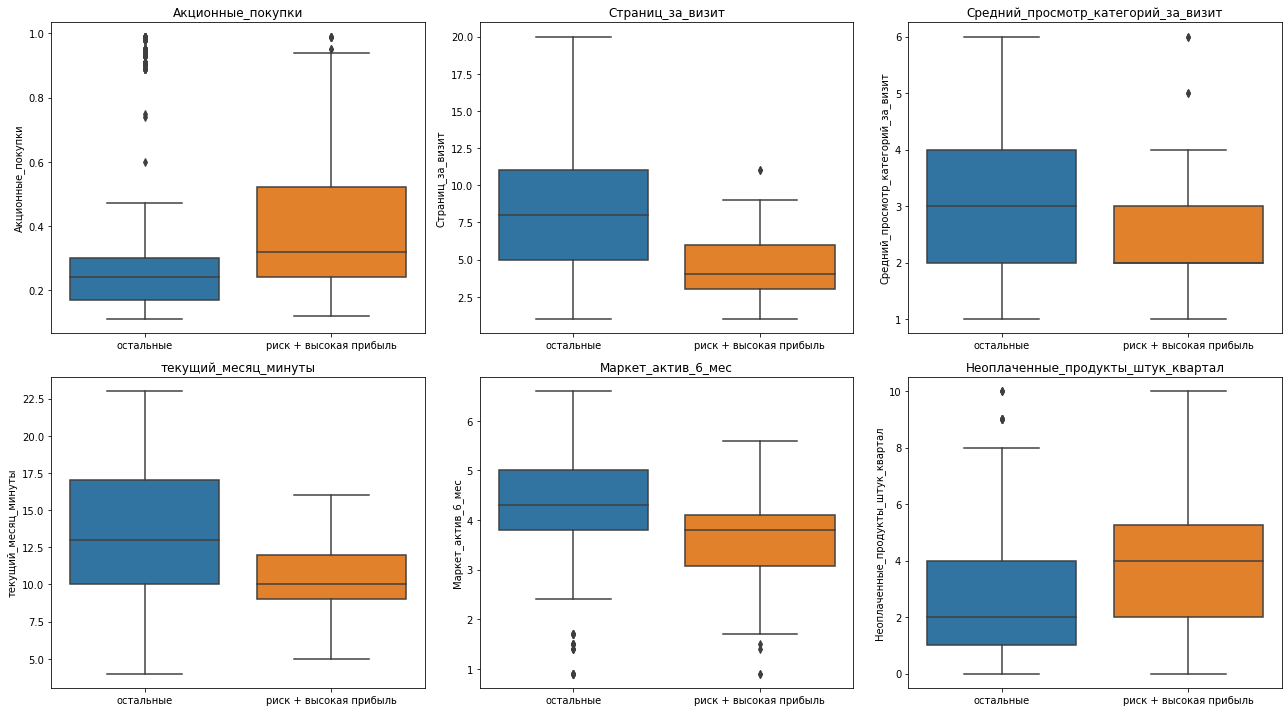

In [101]:
compare_cols = [
    'Акционные_покупки',
    'Страниц_за_визит',
    'Средний_просмотр_категорий_за_визит',
    'текущий_месяц_минуты',
    'Маркет_актив_6_мес',
    'Неоплаченные_продукты_штук_квартал',
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), compare_cols):
    sns.boxplot(data=full_seg, x='сегмент', y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

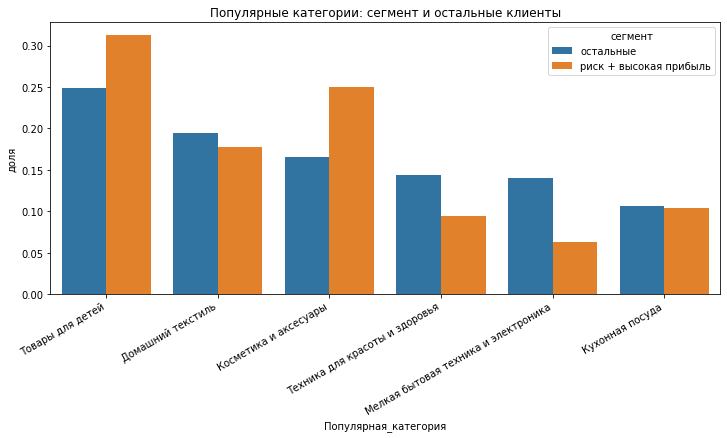

In [102]:
category_share = (
    full_seg.groupby('сегмент')['Популярная_категория']
    .value_counts(normalize=True)
    .rename('доля')
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(data=category_share, x='Популярная_категория', y='доля', hue='сегмент')
plt.xticks(rotation=30, ha='right')
plt.title('Популярные категории: сегмент и остальные клиенты')
plt.show()

In [103]:
full_seg.groupby('сегмент')[compare_cols + ['Прибыль']].median().round(2)

,Акционные_покупки,Страниц_за_визит,Средний_просмотр_категорий_за_визит,текущий_месяц_минуты,Маркет_актив_6_мес,Неоплаченные_продукты_штук_квартал,Прибыль
сегмент,,,,,,,
остальные,0.24,8,3,13,4.3,2,3.94
риск + высокая прибыль,0.32,4,2,10,3.8,4,5.06


Подведём итоги сегментации.

Для дополнительного исследования мы выбрали сегмент клиентов с вероятностью снижения активности не ниже 0.6 и прибылью не ниже 75-го перцентиля. В него попали 96 клиентов, около 7 % активной базы. Выбор объясняется просто: потеря именно этих клиентов обойдётся компании дороже всего, поэтому бюджет на удержание разумно направить в первую очередь на них.

Сегмент заметно отличается от остальных клиентов. Вовлечённость на сайте у него ниже: 4 страницы за визит против 8, две просмотренные категории против трёх, 10 минут на сайте в текущем месяце против 13. Доля акционных покупок выше — 0.32 против 0.24, то есть клиенты чувствительнее к цене. Неоплаченных товаров в корзине вдвое больше: 4 против 2 за квартал. При этом маркетинговых коммуникаций на этих клиентов приходится меньше: 3.8 против 4.3 в месяц. Медианная прибыль — 5.1 у.е. против 3.9 у остальных, так что сегмент действительно ценный.

Что мы предложим бизнесу для этого сегмента:
* Сократить путь до товара: персональные подборки и рекомендации в рассылках и на главной странице. Клиенты сегмента просматривают мало страниц и категорий, поэтому релевантные товары нужно показывать сразу, а не ждать, пока клиент сам их найдёт.
* Напоминать о неоплаченных товарах в корзине, подкрепляя напоминание ограниченным по времени стимулом: скидкой, бесплатной доставкой или бонусными баллами. У сегмента вдвое больше неоплаченных товаров — это самый доступный резерв выручки.
* Заменить массовые акции точечными: сегмент чувствителен к акциям, поэтому персональные промокоды на любимые категории клиента с большой вероятностью сработают, и при этом скидка не раздаётся всем подряд.
* Аккуратно увеличить частоту коммуникаций до среднего уровня по базе, отслеживая отписки и жалобы: сейчас на сегмент приходится меньше маркетинговых активностей, чем на остальных.

Модель стоит применять регулярно: пересчитывать вероятности, например, раз в месяц и обновлять состав сегмента.

## Шаг 9. Общий вывод

Интернет-магазин «В один клик» хочет удерживать активность постоянных клиентов с помощью персонализированных предложений. Нашей задачей было построить модель, предсказывающую вероятность снижения покупательской активности клиента в следующие три месяца, и на её основе выделить сегмент покупателей с рекомендациями по работе с ним.

Мы использовали четыре таблицы: поведение и коммуникации (market_file.csv, 1300 клиентов), выручка по периодам (market_money.csv), время на сайте по периодам (market_time.csv) и прибыль от клиента (money.csv). Пропусков и дубликатов в данных не нашлось; мы исправили две опечатки в значениях («предыдцщий_месяц» и «стандартт») и удалили одного клиента с аномально высокой выручкой. После отбора клиентов, покупавших во все три последних периода, осталось 1296 клиентов. Таблицы мы объединили по id, развернув выручку и время на сайте в отдельные столбцы по периодам. Корреляционный анализ phik показал сильную связь выручки предыдущего и текущего месяцев; признаки мы сохранили, оставив их отбор за моделями.

Для поиска лучшей модели мы построили единый пайплайн: категориальные признаки обрабатываются SimpleImputer и кодировщиком, закреплённым за типом модели: у дерева решений — OrdinalEncoder, у KNN, логистической регрессии и SVC — OneHotEncoder, количественные — SimpleImputer и скейлером (StandardScaler, MinMaxScaler или без масштабирования). GridSearchCV перебирал четыре модели — KNeighborsClassifier, DecisionTreeClassifier, LogisticRegression и SVC — вместе с их гиперпараметрами и вариантами предобработки. Метрикой мы выбрали ROC-AUC: бизнесу важно ранжировать клиентов по риску, а порог классификации будет выбран позже, исходя из бюджета маркетинга.

Лучшей моделью оказалась SVC с ядром RBF (C=0.1, gamma=0.1) с OneHotEncoder и StandardScaler: ROC-AUC 0.912 на кросс-валидации и 0.911 на тестовой выборке.

Анализ важности двумя методами — SHAP и перестановочным — показал, что наибольший вклад в предсказание дают признаки вовлечённости: страницы за визит, время на сайте, число просматриваемых категорий и доля акционных покупок. Тип сервиса, разрешение на рассылку и отдельные категории товаров почти не влияют на предсказание.

Объединив вероятности модели с данными о прибыли, мы выбрали для работы сегмент клиентов с высоким риском снижения активности и высокой прибыльностью (вероятность не ниже 0.6, прибыль в верхнем квартиле) — 96 клиентов, потеря которых обойдётся дороже всего. У сегмента вдвое ниже вовлечённость на сайте, повышенная доля акционных покупок, вдвое больше неоплаченных корзин и при этом меньше маркетинговых коммуникаций, чем у остальных. Мы предложили показывать таким клиентам персональные подборки товаров, напоминать о неоплаченных корзинах с ограниченными по времени стимулами, заменить массовые акции персональными промокодами и выровнять частоту коммуникаций до среднего уровня. Вероятности стоит пересчитывать моделью раз в месяц, обновляя состав сегмента.